# Using ML Models to Predict Customer Churn

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
url = 'https://github.com/IBM/telco-customer-churn-on-icp4d/raw/master/data/Telco-Customer-Churn.csv'

df = pd.read_csv(url)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


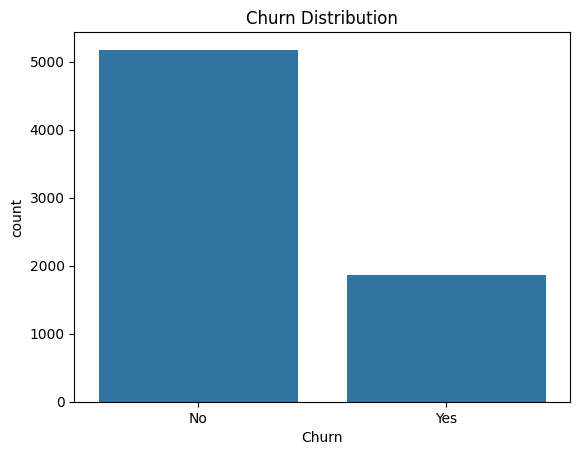

In [21]:
print(df['Churn'].value_counts()) #number of customers churned/not churned
print(df['Churn'].value_counts(normalize=True)) #% of customers churned/not churned

sns.countplot(x='Churn', data=df) #graph to show churn distribution
plt.title('Churn Distribution')
plt.show()

In [22]:
tc = pd.to_numeric(df['TotalCharges'], errors='coerce') #convert datatype to numeric, set errors to NaN

print('Blank TotalCharges:', tc.isnull().sum()) #check for blank values in TotalCharges -- these are brand new customers w/ no charges yet

df.loc[tc.isnull(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']] #display rows with blank TotalCharges

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


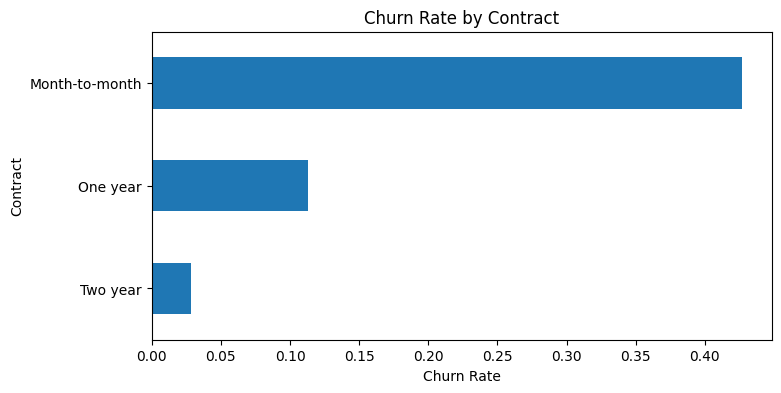

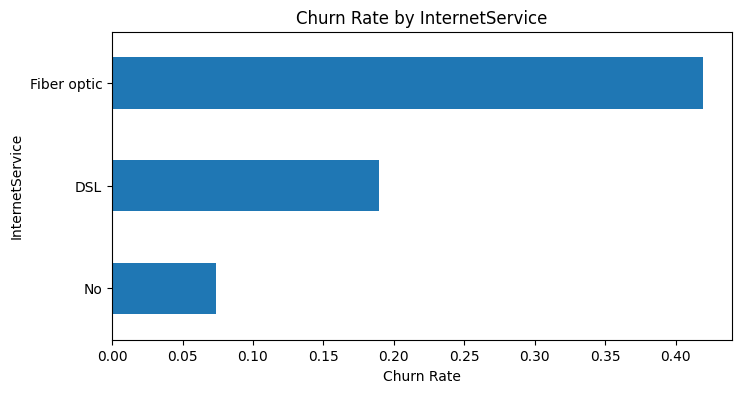

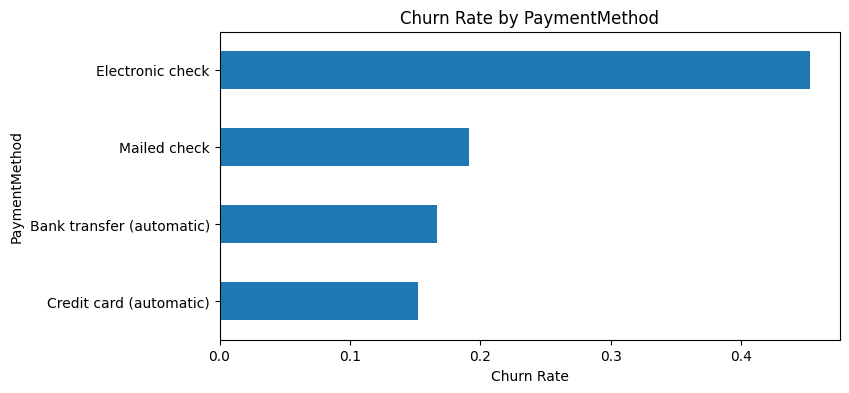

C:\Users\Revenant\AppData\Local\Temp\ipykernel_26172\1391869687.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_churn = df.groupby(tenure_band)['Churn'].apply(lambda s: (s == 'Yes').mean())


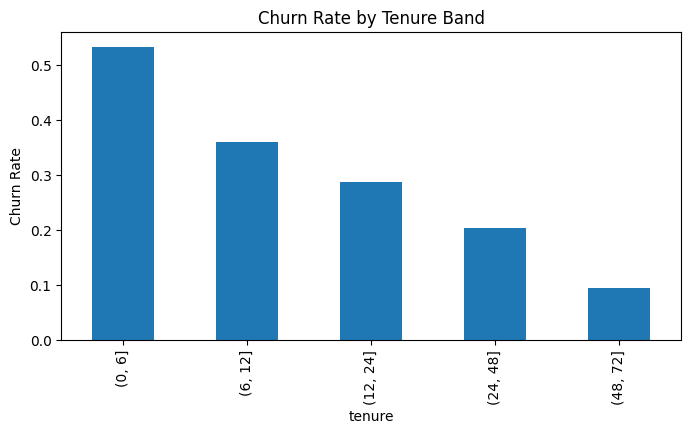

In [23]:
# Determining churn rate by Contract type

def churn_rate(col):
    return df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean()).sort_values()
    return rate

for col in ['Contract', 'InternetService', 'PaymentMethod']:
    rate = churn_rate(col)
    rate.plot(kind='barh', title=f'Churn Rate by {col}', figsize=(8, 4))
    plt.xlabel('Churn Rate')
    plt.show()

tenure_band = pd.cut(df['tenure'], bins=[0, 6, 12, 24, 48, 72])
tenure_churn = df.groupby(tenure_band)['Churn'].apply(lambda s: (s == 'Yes').mean())

tenure_churn.plot(kind='bar', title='Churn Rate by Tenure Band', figsize=(8, 4))
plt.ylabel('Churn Rate')
plt.show()

In [24]:
# Data Cleaning & Preprocessing

data = df.copy()

data = data.drop(['customerID'], axis=1) #drop customerID column

data = data.replace({'No internet service': 'No', 'No phone service': 'No'}) #replace No internet service and No phone service with No

data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce').fillna(0) #replace NaN values in TotalCharges with 0
data['Churn'] = (data['Churn'] == 'Yes').astype(int) #convert Churn column to binary (1 for Yes, 0 for No)

print('Missing values:', data.isna().sum().sum()) #check for missing values

print('Updated DataFrame shape:', data.shape) #display updated DataFrame shape

Missing values: 0
Updated DataFrame shape: (7043, 20)


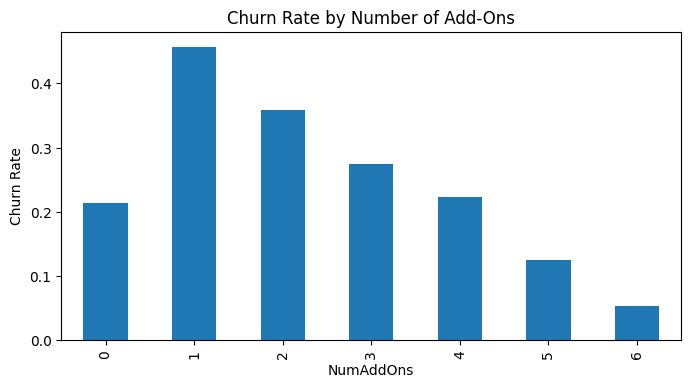

In [25]:
# Feature Engineering

addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

data['NumAddOns'] = (data[addons] == 'Yes').sum(axis=1) #create new column for number of add-ons, since customers w/ more add-ons are more "tied-in"

data['NewCustomer'] = (data['tenure'] <= 6).astype(int) #create new column for new customers (tenure <= 6 months)

# Are customers with more add-ons likely to churn?
data.groupby('NumAddOns')['Churn'].mean().plot(kind='bar', title='Churn Rate by Number of Add-Ons', figsize=(8, 4))
plt.ylabel('Churn Rate')
plt.show() # Churn falls as add-ons increase!

In [26]:
# Encoding Categorical Variables
binary_cols = [c for c in data.columns if data[c].nunique() == 2 and c != 'Churn'] #get binary columns

data[binary_cols] = (data[binary_cols] == 'Yes').astype(int) #encode binary columns as 0/1
data['gender'] = (data['gender'] == 'Male').astype(int) #encode gender column as 0/1, with Male as 1

data = pd.get_dummies(data, 
                      columns=['Contract', 'PaymentMethod', 'InternetService'], 
                      drop_first=True, 
                      dtype=int) #one-hot encode categorical variables with more than 2 categories

print(data.shape)
data.head()

(7043, 26)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,Churn,NumAddOns,NewCustomer,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_Fiber optic,InternetService_No
0,0,0,1,0,1,0,0,0,1,0,...,0,1,0,0,0,0,1,0,0,0
1,0,0,0,0,34,1,0,1,0,1,...,0,2,0,1,0,0,0,1,0,0
2,0,0,0,0,2,1,0,1,1,0,...,1,2,0,0,0,0,0,1,0,0
3,0,0,0,0,45,0,0,1,0,1,...,0,3,0,1,0,0,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,1,0,0,0,0,0,1,0,1,0


In [27]:
# 80/20 Train/Test Split

from sklearn.model_selection import train_test_split

X = data.drop('Churn', axis=1)
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training set shape:', X_train.shape, 'Churn rate:', round(y_train.mean(), 3))
print('Test set shape:', X_test.shape, 'Churn rate:', round(y_test.mean(), 3))

Training set shape: (5634, 25) Churn rate: 0.266
Test set shape: (1409, 25) Churn rate: 0.265


In [28]:
# Feature Scaling w/ StandardScaler for other numeric variables

from sklearn.preprocessing import StandardScaler

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumAddOns'] #numeric columns to scale
scaler = StandardScaler()

X_train_s, X_test_s = X_train.copy(), X_test.copy() #create copies of X_train and X_test to scale
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols]) #use transform() on test set to avoid data leakage
X_train_s[num_cols].describe().round(2) #check scaled values

,tenure,MonthlyCharges,TotalCharges,NumAddOns
count,5634.00,5634.00,5634.00,5634.00
mean,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.33,-1.55,-1.01,-1.10
25%,-0.96,-0.97,-0.83,-1.10
50%,-0.14,0.19,-0.39,-0.02
75%,0.93,0.83,0.67,0.52
max,1.62,1.79,2.83,2.14


In [29]:
# Developing the Models

# Train 3 different classification algorithms: Logistic Regression, Random Forest, kNN. Test hyperparameters using 5-fod CV on training set. Evaluate performance on test set using F1 score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) #5-fold CV with stratified sampling

searches = {
    'Logistic Regression': 
        (LogisticRegression(max_iter=2000), 
         {'C': [0.01, 0.1, 1, 10], 
          'class_weight': [None, 'balanced']}, 
          X_train_s),
    'Random Forest': 
        (RandomForestClassifier(random_state=42, n_jobs=-1), 
         {'n_estimators': [200, 400], ''
         'max_depth': [5, 8, None], 
         'min_samples_leaf': [1, 5, 10], 
         'class_weight': [None, 'balanced']}, 
         X_train_s),
    'kNN': 
        (KNeighborsClassifier(), 
         {'n_neighbors': [3, 5, 7], 
          'weights': ['uniform', 'distance']}, 
          X_train_s)
}

best_models = {}

for name, (model, grid, Xtr) in searches.items():
    gs = GridSearchCV(model, grid, scoring='f1', cv=cv, n_jobs=-1)
    gs.fit(Xtr, y_train)
    best_models[name] = gs.best_estimator_ 
    print(f'{name}: best CV F1 = {gs.best_score_:.3f}  settings = {gs.best_params_}')


Logistic Regression: best CV F1 = 0.623  settings = {'C': 0.1, 'class_weight': 'balanced'}
Random Forest: best CV F1 = 0.629  settings = {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}
kNN: best CV F1 = 0.538  settings = {'n_neighbors': 7, 'weights': 'uniform'}


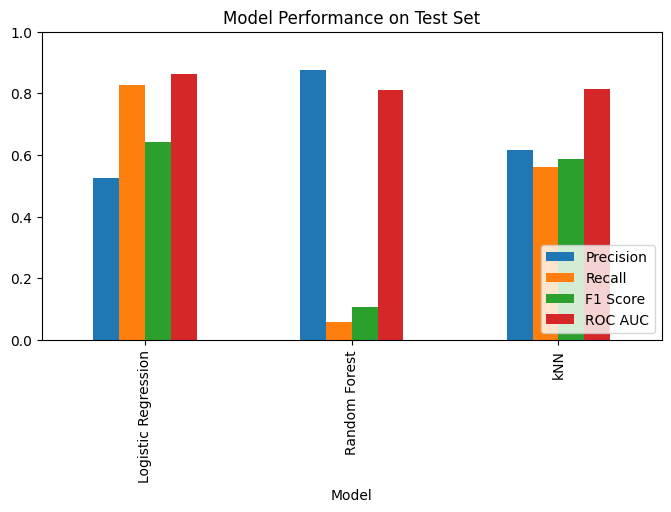

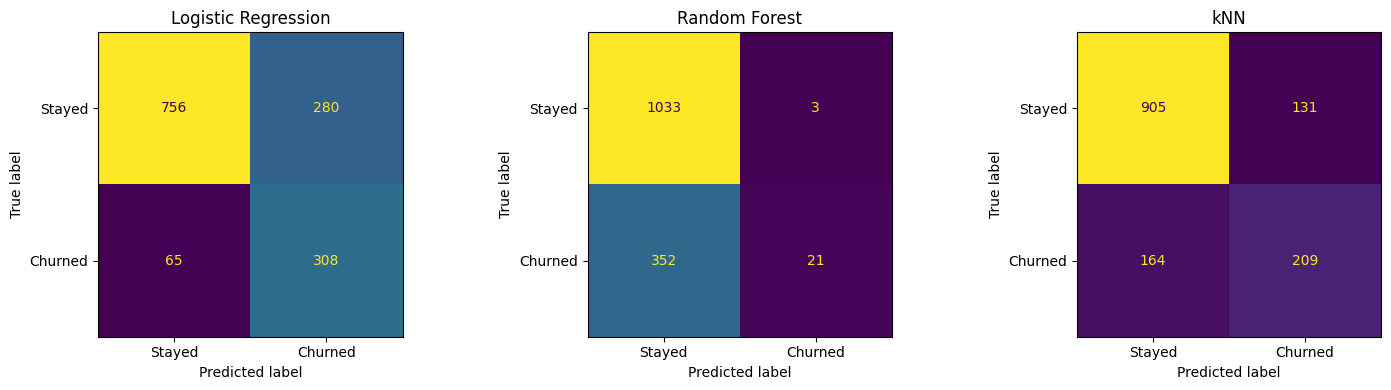

In [30]:
# Evaluation on the Test Set

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

test_sets = {'Logistic Regression': X_test_s, 'Random Forest': X_test, 'kNN': X_test_s}

rows = []

for name, model in best_models.items():
    Xte = test_sets[name]
    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, model.predict_proba(Xte)[:, 1])
    })

results = pd.DataFrame(rows).set_index('Model').round(3)
results.sort_values('F1 Score', ascending=False)

results[['Precision', 'Recall', 'F1 Score', 'ROC AUC']].plot(kind='bar', figsize=(8, 4), title='Model Performance on Test Set')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, test_sets[name], y_test, ax=ax, display_labels=['Stayed', 'Churned'], colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [31]:
# Choosing the Right Model

from sklearn.model_selection import cross_val_score

for name, Xtr in [('Logistic Regression', X_train_s), ('Random Forest', X_train), ('kNN', X_train_s)]:
    model = best_models[name]
    scores = cross_val_score(model, Xtr, y_train, cv=cv, scoring='f1', n_jobs=-1)
    print(f'{name:20s} F1 per fold: {scores.round(3)}  mean {scores.mean():.3f}  std {scores.std():.3f}')

Logistic Regression  F1 per fold: [0.589 0.626 0.626 0.62  0.656]  mean 0.623  std 0.021
Random Forest        F1 per fold: [0.593 0.638 0.626 0.631 0.655]  mean 0.629  std 0.020
kNN                  F1 per fold: [0.545 0.541 0.517 0.537 0.549]  mean 0.538  std 0.011


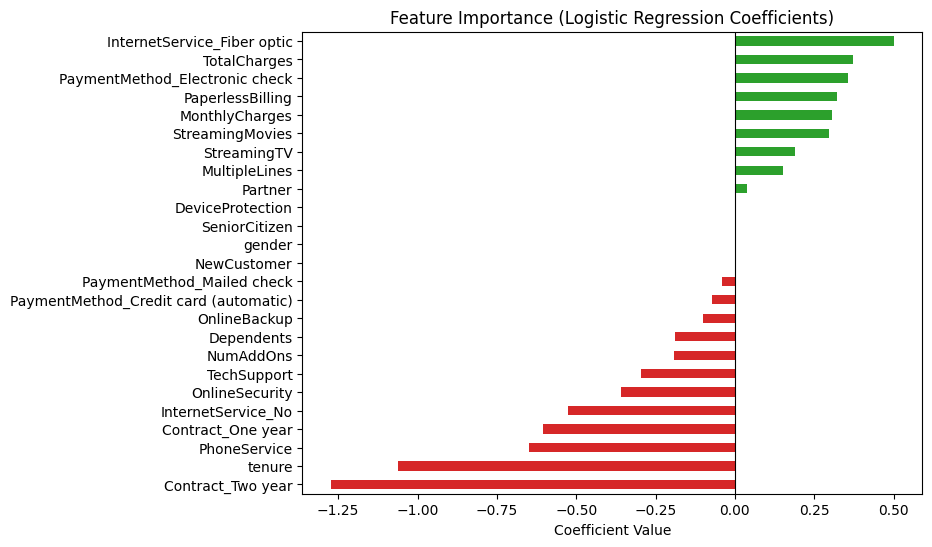

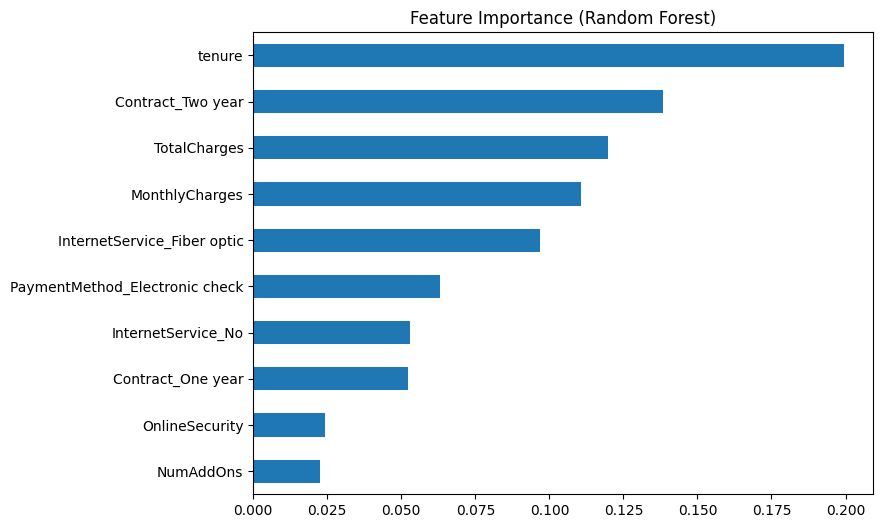

In [32]:
# Key Insights from the Right Model

final = best_models['Logistic Regression'] #choose Logistic Regression as final model based on F1 score and interpretability

coefs = pd.Series(final.coef_[0], index=X_train_s.columns).sort_values()
colors = ['tab:green' if c > 0 else 'tab:red' for c in coefs]

coefs.plot(kind='barh', color=colors, figsize=(8, 6), title='Feature Importance (Logistic Regression Coefficients)')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient Value')
plt.show()

pd.DataFrame({'Coefficient': coefs, 'Odds Ratio': np.exp(coefs)}).round(2).sort_values('Coefficient')

# Cross-checking with Feature Importance from the Random Forest model

rf_imp = pd.Series(best_models['Random Forest'].feature_importances_, index=X_train.columns).sort_values(ascending=False)

rf_imp.sort_values().tail(10).plot(kind='barh', figsize=(8, 6), title='Feature Importance (Random Forest)')

plt.show()

In [33]:
# Checking Prediction Patterns

prob = final.predict_proba(X_test_s)[:, 1] #get predicted probabilities for the positive class (Churn = 1)

band = pd.cut(prob, 
              bins=[0, 0.3, 0.5, 0.7, 1.0],
              labels=['Low (<30%)', 'Medium (30-50%)', 'High (50-70%)', 'Very High (>70%)'])

summary = pd.DataFrame({'Customers': y_test.groupby(band, observed=False).size(),
                        'Actual Churners': y_test.groupby(band, observed=False).sum(),
                        'Actual Churn Rate': y_test.groupby(band, observed=False).mean()}).round(3)

print(summary)

                  Customers  Actual Churners  Actual Churn Rate
Low (<30%)              584               22              0.038
Medium (30-50%)         237               43              0.181
High (50-70%)           237               76              0.321
Very High (>70%)        351              232              0.661
